# v2-02 · Sequential idle delays: composed per-segment corrections vs. one end correction

**What changed vs. `DELAY_CAPTURE_sequential_approach.ipynb`**

1. `build_Q` in the old notebook was wrong in three ways (it multiplied by $M$ twice, used a quadratic polarisation identity on a quartic function, and then *maximised* an error-like quantity). For a 100-dt delay with $M\approx I$ it returned $\lambda_{\max}=3.8$ and a near-$\pi$ rotation — that is the stage-1 blow-up in Table II of draft 7. Replaced by the verified `quasi_inverse()`.
2. Two corrected strategies are now compared on the same prefixes:
   * **sequential**: $\mathcal D_{t_1} V_{t_1}\mathcal D_{t_2} V_{t_2}\cdots$, each $V_{t_k}$ learned from the isolated delay $t_k$ (the draft-7 protocol);
   * **cumulative**: $\mathcal D_{t_1}\cdots\mathcal D_{t_k}$ followed by a single $V_{T_k}$ learned from the cumulative idle time $T_k$.
   The difference between the two isolates the cost of composing independently learned gates.
3. All characterisation circuits in one job, all validation circuits in a second job; errors, metadata and job IDs recorded.

**What to send back:** `results_sequential_delay_<backend>.json` and the printed table.


In [ ]:
EXTRA_PKGS = []
# Colab / fresh environment: install once (comment out if already installed)
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "qiskit>=1.4", "qiskit-aer", "qiskit-ibm-runtime>=0.40", "matplotlib", "pandas"] + EXTRA_PKGS,
               check=False)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'qiskit>=1.4', 'qiskit-aer', 'qiskit-ibm-runtime>=0.40', 'matplotlib', 'pandas'], returncode=0)

## Shared, verified MSTD / quasi-inverse routines (identical in all v2 notebooks)

In [ ]:
# =============================================================================
#  MSTD quasi-inverse: shared, verified routines  (v2, 2026-11-05)
#  This block is pasted verbatim into every v2 notebook. Do not edit one copy
#  without editing the others.
#
#  Conventions (identical to the paper):
#    rho(r) = (I + r.sigma)/2,   channel  r -> M r + c
#    D^2(M,c) = [Tr(M M^T) - 2 Tr M + 3]/20 + |c|^2/4           (Bloch-ball MSTD)
#    V(x) = x0 I + i (x1 X + x2 Y + x3 Z),   |x| = 1             (unitary recovery)
#    V rho(r) V^dag = rho(R_V r),   V o E  ->  (R_V M, R_V c)
#
#  Key identity used for the quasi-inverse:
#    D^2(R M, R c) = D^2(M,c) - (1/10)[Tr(R M) - Tr M]           (R orthogonal)
#  so maximising the MSTD reduction  Delta D^2 = (1/10)[Tr(R_V M) - Tr M]
#  is the same as maximising Tr(R_V M), which is an exact quadratic form in x:
#    Delta D^2(x) = (1/5) x^T Qhat x,
#    Qhat_00 = 0,  Qhat_vv = (M + M^T)/2 - Tr(M) I_3,
#    Qhat_01 = -(M_23 - M_32)/2, Qhat_02 = -(M_31 - M_13)/2, Qhat_03 = -(M_12 - M_21)/2
#  (indices 1,2,3 = x,y,z).  The optimum is the top eigenvector of Qhat and
#  Delta D^2_max = lambda_max(Qhat)/5.  Because the identity (x = e_0) gives
#  x^T Qhat x = 0, lambda_max >= 0 always, and lambda_max = 0 means "do nothing".
#
#  NOTE: the expression in draft 7 of the paper (prefactor 2/5, diagonal block
#  (M+M^T)/2 - Tr(M)/2 I, off-diagonals -1/4 (...)) is NOT the quadratic form of
#  Delta D^2; self_test() below checks the one used here against brute force.
# =============================================================================
import json, math, time, datetime
import numpy as np

I2 = np.eye(2, dtype=complex)
PX = np.array([[0, 1], [1, 0]], dtype=complex)
PY = np.array([[0, -1j], [1j, 0]], dtype=complex)
PZ = np.array([[1, 0], [0, -1]], dtype=complex)
PAULIS = [PX, PY, PZ]


def mstd(M, c):
    """Bloch-ball mean-square trace distance of the affine channel (M, c)."""
    M = np.asarray(M, float); c = np.asarray(c, float).reshape(3)
    return float((np.trace(M @ M.T) - 2.0 * np.trace(M) + 3.0) / 20.0 + c @ c / 4.0)


def unitary_from_x(x):
    """V = x0 I + i(x1 X + x2 Y + x3 Z), normalised."""
    x = np.asarray(x, float); x = x / np.linalg.norm(x)
    return x[0] * I2 + 1j * (x[1] * PX + x[2] * PY + x[3] * PZ)


def rotation_from_unitary(V):
    """SO(3) matrix R_V with V rho(r) V^dag = rho(R_V r)."""
    return np.array([[0.5 * np.trace(si @ V @ sj @ V.conj().T).real for sj in PAULIS] for si in PAULIS])


def build_Qhat(M):
    """Exact 4x4 symmetric matrix with Delta D^2(x) = (1/5) x^T Qhat x."""
    M = np.asarray(M, float)
    Q = np.zeros((4, 4))
    Q[1:, 1:] = 0.5 * (M + M.T) - np.trace(M) * np.eye(3)
    Q[0, 1] = Q[1, 0] = -(M[1, 2] - M[2, 1]) / 2.0
    Q[0, 2] = Q[2, 0] = -(M[2, 0] - M[0, 2]) / 2.0
    Q[0, 3] = Q[3, 0] = -(M[0, 1] - M[1, 0]) / 2.0
    return Q


def quasi_inverse(M, c, min_gain=1e-4):
    """Optimal unitary quasi-inverse of the affine channel (M, c).

    Returns dict with x, V, R, Q, lambda_max, D2_raw, D2_corrected, delta_D2 (= delta_D2_predicted).
    If the best achievable reduction is below `min_gain` the identity is returned (nothing to correct).
    """
    M = np.asarray(M, float); c = np.asarray(c, float).reshape(3)
    Q = build_Qhat(M)
    evals, evecs = np.linalg.eigh(Q)
    lam = float(evals[-1]); x = np.real(evecs[:, -1]); x /= np.linalg.norm(x)
    if lam / 5.0 <= min_gain:           # channel is already best left alone
        lam = 0.0; x = np.array([1.0, 0.0, 0.0, 0.0])
    if x[0] < 0: x = -x                 # fix the global-phase sign convention
    V = unitary_from_x(x); R = rotation_from_unitary(V)
    D2_raw = mstd(M, c); D2_qi = mstd(R @ M, R @ c)
    out = dict(x=x, V=V, R=R, Q=Q, lambda_max=lam, D2_raw=D2_raw,
               D2_corrected=D2_qi, delta_D2=D2_raw - D2_qi, delta_D2_predicted=lam / 5.0)
    # internal consistency: the closed form must reproduce the direct evaluation
    assert abs(out["delta_D2"] - out["delta_D2_predicted"]) < 1e-9, "Qhat inconsistent with direct MSTD"
    assert out["delta_D2"] <= D2_raw + 1e-12, "reduction larger than the raw MSTD (impossible)"
    assert np.linalg.norm(V.conj().T @ V - I2) < 1e-12
    return out


def affine_from_tomography(r0, r1, rp, ry):
    """(M, c) from the Bloch vectors of the outputs for inputs |0>,|1>,|+>,|+y>."""
    r0, r1, rp, ry = (np.asarray(v, float) for v in (r0, r1, rp, ry))
    c = 0.5 * (r0 + r1)
    M = np.column_stack([rp - c, ry - c, 0.5 * (r0 - r1)])
    return M, c


def affine_from_pairs(r_in, r_out):
    """Least-squares (M, c) from any set of (input, output) Bloch vectors (>= 4 inputs)."""
    r_in = np.asarray(r_in, float); r_out = np.asarray(r_out, float)
    A = np.hstack([r_in, np.ones((len(r_in), 1))])           # [r | 1]
    sol, *_ = np.linalg.lstsq(A, r_out, rcond=None)          # sol^T = [M | c]
    return sol[:3].T, sol[3]


def expectation_and_se(counts, key0="0", key1="1"):
    """<P> = (n0 - n1)/N and its binomial standard error."""
    n0 = counts.get(key0, 0); n1 = counts.get(key1, 0); N = n0 + n1
    if N == 0: return float("nan"), float("nan")
    p = n0 / N; e = 2 * p - 1
    se = 2.0 * math.sqrt(max(p * (1 - p), 0.25 / N) / N)     # floor avoids se = 0 at p in {0,1}
    return e, se


def trace_distance(r1, r2):
    return 0.5 * float(np.linalg.norm(np.asarray(r1, float) - np.asarray(r2, float)))


def trace_distance_se(r1, r2, se2):
    """Propagated 1-sigma error of D(r1, r2) when r2 has component errors se2."""
    d = np.asarray(r1, float) - np.asarray(r2, float); n = np.linalg.norm(d)
    if n < 1e-12: return 0.5 * float(np.linalg.norm(se2))
    return 0.5 * float(math.sqrt(np.sum((d / n) ** 2 * np.asarray(se2, float) ** 2)))


def sampled_mstd(M, c, n=20000, seed=0):
    """Monte-Carlo D^2 over the uniform Bloch ball (cross-check of the closed form)."""
    rng = np.random.default_rng(seed)
    v = rng.normal(size=(n, 3)); v /= np.linalg.norm(v, axis=1)[:, None]
    r = v * rng.uniform(0, 1, n)[:, None] ** (1 / 3)
    d = r - (r @ np.asarray(M, float).T + np.asarray(c, float))
    return float(np.mean(np.sum(d * d, axis=1)) / 4.0)


def backend_metadata(backend, qubits):
    """Backend name, dt, and T1/T2/readout/gate errors for the physical qubits used."""
    meta = {"backend": getattr(backend, "name", str(backend)), "timestamp_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
            "qubits": list(qubits)}
    try:
        meta["dt_seconds"] = float(backend.dt) if backend.dt is not None else None
    except Exception:
        meta["dt_seconds"] = None
    try:
        props = backend.properties()
        meta["calibration"] = {}
        for q in qubits:
            meta["calibration"][int(q)] = {
                "T1_us": props.t1(q) * 1e6, "T2_us": props.t2(q) * 1e6,
                "readout_error": props.readout_error(q),
                "sx_error": props.gate_error("sx", [q]) if "sx" in {g.gate for g in props.gates} else None}
    except Exception as exc:
        meta["calibration_error"] = str(exc)
    return meta


class NpEncoder(json.JSONEncoder):
    def default(self, o):
        if isinstance(o, np.ndarray):
            return o.tolist() if not np.iscomplexobj(o) else {"re": o.real.tolist(), "im": o.imag.tolist()}
        if isinstance(o, (np.floating, np.integer)): return o.item()
        if isinstance(o, complex): return {"re": o.real, "im": o.imag}
        return super().default(o)


def save_results(obj, filename):
    with open(filename, "w") as fh:
        json.dump(obj, fh, cls=NpEncoder, indent=1)
    print("saved", filename)
    try:                                   # Colab: trigger a download so the file can be sent back
        from google.colab import files
        files.download(filename)
    except Exception:
        pass


def self_test(n_random=200, seed=1):
    """Check Qhat against brute-force optimisation on random channels and on known cases."""
    rng = np.random.default_rng(seed)
    # exact quadratic form on random affine maps
    for _ in range(n_random):
        M = rng.normal(size=(3, 3)) * 0.5; c = rng.normal(size=3) * 0.1
        Q = build_Qhat(M)
        for _ in range(3):
            x = rng.normal(size=4); x /= np.linalg.norm(x)
            R = rotation_from_unitary(unitary_from_x(x))
            dd = mstd(M, c) - mstd(R @ M, R @ c)
            assert abs(dd - x @ Q @ x / 5.0) < 1e-10, "Qhat is not the quadratic form of Delta D^2"
        qi = quasi_inverse(M, c)
        best = min(mstd(rotation_from_unitary(unitary_from_x(v)) @ M, rotation_from_unitary(unitary_from_x(v)) @ c)
                   for v in rng.normal(size=(3000, 4)))
        assert qi["D2_corrected"] <= best + 1e-9, "eigenvector is not the optimum"
    # bit flip p=0.55: M=diag(1,-0.1,-0.1) -> V = X, Delta D^2 = 0.04
    qi = quasi_inverse(np.diag([1, -0.1, -0.1]), np.zeros(3))
    assert abs(qi["delta_D2"] - 0.04) < 1e-12 and abs(abs(qi["x"][1]) - 1) < 1e-9
    # near-identity channel -> V = identity
    qi = quasi_inverse(0.97 * np.eye(3), np.array([0, 0, 0.03]))
    assert qi["lambda_max"] == 0.0 and qi["x"][0] == 1.0
    # sampled MSTD agrees with closed form
    M = rng.normal(size=(3, 3)) * 0.4; c = rng.normal(size=3) * 0.1
    assert abs(sampled_mstd(M, c, 200000) - mstd(M, c)) < 2e-3
    print("mstd_qi_common self-test passed")



self_test()


mstd_qi_common self-test passed


## Backend

In [ ]:
# ---------------------------------------------------------------------------
# Backend selection.  NEVER paste a token into this notebook (two earlier
# notebooks had tokens committed in plain text -- those tokens must be revoked).
# Run ONCE in a separate scratch cell, then delete that cell:
#   from qiskit_ibm_runtime import QiskitRuntimeService
#   QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token="...", overwrite=True)
# Alternatively set the environment variable IBM_QUANTUM_TOKEN (Colab: use userdata secrets).
# ---------------------------------------------------------------------------
import os
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate
from qiskit.transpiler import generate_preset_pass_manager

USE_SIMULATOR = False            # <-- set False for the real QPU run
BACKEND_NAME  = "ibm_fez"       # the paper's primary device; keep all experiments on one device
SHOTS         = 4096

if USE_SIMULATOR:
    from qiskit_aer import AerSimulator
    from qiskit_ibm_runtime.fake_provider import FakeFez
    from qiskit_aer.primitives import SamplerV2 as Sampler
    fake = FakeFez()
    backend = AerSimulator.from_backend(fake)        # noise model + coupling map of ibm_fez
    backend.name = "aer(" + fake.name + ")"
    cal_backend = fake                               # properties() for metadata
    sampler = Sampler.from_backend(fake)
else:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
    token = os.environ.get("IBM_QUANTUM_TOKEN")
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token) if token else QiskitRuntimeService()
    backend = service.backend(BACKEND_NAME)
    cal_backend = backend
    sampler = Sampler(mode=backend)

print("Backend:", backend.name, "| simulator:", USE_SIMULATOR, "| shots:", SHOTS)

JOB_LOG = []   # every submitted job: id, purpose, number of circuits

def run_batch(circuits, purpose, physical_qubits=None, optimization_level=1):
    """Transpile + run one list of circuits; returns a list of counts dicts (same order)."""
    target = cal_backend if USE_SIMULATOR else backend
    pm = generate_preset_pass_manager(backend=target, optimization_level=optimization_level,
                                      initial_layout=physical_qubits)
    isa = pm.run(circuits)
    # sanity: delays must survive transpilation
    for q0, q1 in zip(circuits, isa):
        n_delay0 = sum(1 for inst in q0.data if inst.operation.name == "delay")
        n_delay1 = sum(1 for inst in q1.data if inst.operation.name == "delay")
        assert n_delay1 >= n_delay0, "transpiler removed a delay -- lower optimization_level"
    job = sampler.run(isa, shots=SHOTS)
    jid = job.job_id() if hasattr(job, "job_id") else "simulator"
    JOB_LOG.append({"job_id": jid, "purpose": purpose, "n_circuits": len(isa),
                    "depths": [c.depth() for c in isa], "two_qubit_gates": [c.num_nonlocal_gates() for c in isa],
                    "physical_qubits": [sorted({q._index if hasattr(q, "_index") else backend_index(c, q)
                                                for inst in c.data for q in inst.qubits if inst.operation.name == "measure"})
                                        for c in isa]})
    print(f"[{purpose}] job {jid}: {len(isa)} circuits submitted")
    res = job.result()
    out = []
    for pub in res:
        data = pub.data
        reg = [k for k in data.keys()][0]
        out.append(getattr(data, reg).get_counts())
    return out

def backend_index(circ, q):
    return circ.find_bit(q).index


qiskit_runtime_service.__init__:WARNING:2026-11-06 19:41:56,717: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-06 19:41:56,718: Using instance: open-instance, plan: open


Backend: ibm_fez | simulator: False | shots: 4096


/tmp/ipykernel_1072/498519058.py:33: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


## Tomography helpers

In [ ]:
# ---------------------------------------------------------------------------
# State preparation / measurement helpers (single logical qubit, register "meas")
# ---------------------------------------------------------------------------
PAULI_STATES = {            # name: (prep gates, Bloch vector)
    "0":  ([],            np.array([0, 0, 1.0])),
    "1":  (["x"],         np.array([0, 0, -1.0])),
    "+":  (["h"],         np.array([1.0, 0, 0])),
    "-":  (["x", "h"],    np.array([-1.0, 0, 0])),
    "+y": (["h", "s"],    np.array([0, 1.0, 0])),
    "-y": (["h", "sdg"],  np.array([0, -1.0, 0])),
}
CHAR_INPUTS = ["0", "1", "+", "+y"]      # minimal set that determines (M, c)
VAL_INPUTS  = list(PAULI_STATES)         # all six Pauli eigenstates for validation

def prepare(qc, q, state):
    for g in PAULI_STATES[state][0]:
        getattr(qc, g)(q)

def rotate_to_z(qc, q, basis):
    if basis == "X":   qc.h(q)
    elif basis == "Y": qc.sdg(q); qc.h(q)       # (H S^dag)^dag Z (H S^dag) = Y
    elif basis != "Z": raise ValueError(basis)

def bloch_from_counts(counts_xyz):
    """[counts_X, counts_Y, counts_Z] -> (r, se)"""
    vals = [expectation_and_se(c) for c in counts_xyz]
    return np.array([v[0] for v in vals]), np.array([v[1] for v in vals])


## Parameters

In [ ]:
QUBIT = 0
DELAY_SEQUENCE = [100, 500, 1000, 2000, 5000]          # segment lengths, dt
CUMULATIVE = list(np.cumsum(DELAY_SEQUENCE))           # 100, 600, 1600, 3600, 8600
CHAR_DELAYS = sorted(set(DELAY_SEQUENCE) | set(int(t) for t in CUMULATIVE))
TEST_STATE = "+"
dt_s = getattr(cal_backend, "dt", None)
print("characterise delays (dt):", CHAR_DELAYS, "| dt =", dt_s)


characterise delays (dt): [100, 500, 600, 1000, 1600, 2000, 3600, 5000, 8600] | dt = 4e-09


## Job 1 - characterise segments and cumulative delays

In [ ]:
def char_circuit(state, basis, delay_dt):
    qr = QuantumRegister(1, "q"); cr = ClassicalRegister(1, "meas")
    qc = QuantumCircuit(qr, cr); prepare(qc, qr[0], state); qc.barrier()
    qc.delay(delay_dt, qr[0], unit="dt"); qc.barrier(); rotate_to_z(qc, qr[0], basis); qc.measure(qr[0], cr[0])
    return qc

def prefix_circuit(k, basis, mode):
    """mode: 'raw' | 'sequential' | 'cumulative'  (k = number of segments, 1..5)"""
    qr = QuantumRegister(1, "q"); cr = ClassicalRegister(1, "meas")
    qc = QuantumCircuit(qr, cr); prepare(qc, qr[0], TEST_STATE); qc.barrier()
    for d in DELAY_SEQUENCE[:k]:
        qc.delay(d, qr[0], unit="dt"); qc.barrier()
        if mode == "sequential":
            qc.append(UnitaryGate(CH[d]["qi"]["V"], label=f"V_{d}"), [qr[0]]); qc.barrier()
    if mode == "cumulative":
        qc.append(UnitaryGate(CH[int(CUMULATIVE[k-1])]["qi"]["V"], label=f"V_cum{CUMULATIVE[k-1]}"), [qr[0]]); qc.barrier()
    rotate_to_z(qc, qr[0], basis); qc.measure(qr[0], cr[0])
    return qc

# ---- Job 1: characterise every segment and every cumulative delay, plus raw prefixes ----
circuits, index = [], []
for d in CHAR_DELAYS:
    for s in CHAR_INPUTS:
        for b in "XYZ":
            circuits.append(char_circuit(s, b, d)); index.append(("char", d, s, b))
for k in range(1, len(DELAY_SEQUENCE) + 1):
    for b in "XYZ":
        circuits.append(prefix_circuit(k, b, "raw")); index.append(("raw", k, TEST_STATE, b))
counts = run_batch(circuits, "characterisation+raw prefixes", physical_qubits=[QUBIT])
CNT = {}
for key, cnt in zip(index, counts):
    CNT[key] = cnt

CH = {}
for d in CHAR_DELAYS:
    r = {s: bloch_from_counts([CNT[("char", d, s, b)] for b in "XYZ"]) for s in CHAR_INPUTS}
    M, c = affine_from_tomography(r["0"][0], r["1"][0], r["+"][0], r["+y"][0])
    qi = quasi_inverse(M, c)
    CH[d] = dict(M=M, c=c, bloch=r, qi=qi)
    print(f"delay {d:>5} dt: D2_raw={qi['D2_raw']:.4f}  lambda_max={qi['lambda_max']:.4f}  predicted D2_QI={qi['D2_corrected']:.4f}  x={np.round(qi['x'],3)}")


[characterisation+raw prefixes] job dbn2r85t7fqc73airg9g: 123 circuits submitted
delay   100 dt: D2_raw=0.0029  lambda_max=0.0052  predicted D2_QI=0.0019  x=[ 0.999  0.    -0.016  0.051]
delay   500 dt: D2_raw=0.0454  lambda_max=0.0257  predicted D2_QI=0.0402  x=[0.983 0.013 0.001 0.183]
delay   600 dt: D2_raw=0.0620  lambda_max=0.0322  predicted D2_QI=0.0556  x=[ 0.97  -0.004 -0.018  0.241]
delay  1000 dt: D2_raw=0.1023  lambda_max=0.0063  predicted D2_QI=0.1011  x=[ 0.923  0.01  -0.018  0.384]
delay  1600 dt: D2_raw=0.1058  lambda_max=0.0000  predicted D2_QI=0.1058  x=[1. 0. 0. 0.]
delay  2000 dt: D2_raw=0.1128  lambda_max=0.0012  predicted D2_QI=0.1126  x=[ 0.66   0.015 -0.008  0.751]
delay  3600 dt: D2_raw=0.1259  lambda_max=0.0209  predicted D2_QI=0.1218  x=[0.758 0.011 0.004 0.652]
delay  5000 dt: D2_raw=0.1391  lambda_max=0.0007  predicted D2_QI=0.1390  x=[ 0.989  0.014 -0.009  0.15 ]
delay  8600 dt: D2_raw=0.1848  lambda_max=0.0262  predicted D2_QI=0.1795  x=[ 0.537 -0.029 -0. 

## Job 2 - corrected prefixes, both strategies

[corrected prefixes] job dbn2urdt7fqc73airlsg: 30 circuits submitted


,stage,cumulative_dt,D_raw,D_raw_se,D_sequential,D_sequential_se,D_cumulative,D_cumulative_se,pred_D2_cum_raw,pred_D2_cum_QI
0,1,100,0.072,0.006,0.056,0.004,0.049,0.004,0.003,0.002
1,2,600,0.382,0.008,0.371,0.008,0.350,0.007,0.062,0.056
2,3,1600,0.513,0.008,0.490,0.008,0.516,0.008,0.106,0.106
3,4,3600,0.508,0.008,0.511,0.008,0.521,0.008,0.126,0.122
4,5,8600,0.561,0.008,0.556,0.008,0.546,0.008,0.185,0.180


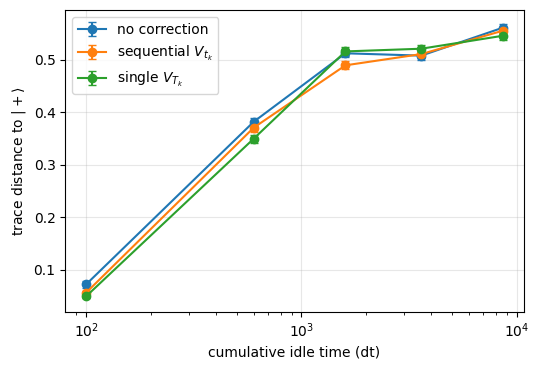

In [ ]:
# ---- Job 2: corrected prefixes, both strategies ----
circuits, index = [], []
for k in range(1, len(DELAY_SEQUENCE) + 1):
    for mode in ("sequential", "cumulative"):
        for b in "XYZ":
            circuits.append(prefix_circuit(k, b, mode)); index.append((mode, k, TEST_STATE, b))
counts = run_batch(circuits, "corrected prefixes", physical_qubits=[QUBIT])
for key, cnt in zip(index, counts):
    CNT[key] = cnt

import pandas as pd
r_in = PAULI_STATES[TEST_STATE][1]; rows = []
for k in range(1, len(DELAY_SEQUENCE) + 1):
    row = dict(stage=k, cumulative_dt=int(CUMULATIVE[k-1]))
    for mode in ("raw", "sequential", "cumulative"):
        r, se = bloch_from_counts([CNT[(mode, k, TEST_STATE, b)] for b in "XYZ"])
        row[f"D_{mode}"] = trace_distance(r_in, r); row[f"D_{mode}_se"] = trace_distance_se(r_in, r, se)
        row[f"r_{mode}"] = np.round(r, 3)
    row["pred_D2_cum_raw"] = CH[int(CUMULATIVE[k-1])]["qi"]["D2_raw"]
    row["pred_D2_cum_QI"]  = CH[int(CUMULATIVE[k-1])]["qi"]["D2_corrected"]
    rows.append(row)
TABLE = pd.DataFrame(rows); pd.set_option("display.precision", 3)
display(TABLE[["stage", "cumulative_dt", "D_raw", "D_raw_se", "D_sequential", "D_sequential_se", "D_cumulative", "D_cumulative_se", "pred_D2_cum_raw", "pred_D2_cum_QI"]])

import matplotlib.pyplot as plt
plt.figure(figsize=(5.5, 3.8))
for mode, lab in (("raw", "no correction"), ("sequential", "sequential $V_{t_k}$"), ("cumulative", "single $V_{T_k}$")):
    plt.errorbar(TABLE.cumulative_dt, TABLE[f"D_{mode}"], yerr=TABLE[f"D_{mode}_se"], marker="o", capsize=3, label=lab)
plt.xscale("log"); plt.xlabel("cumulative idle time (dt)"); plt.ylabel(r"trace distance to $|+\rangle$"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig("fig_sequential_delay_v2.pdf"); plt.show()


## Export results (send this file back)

In [ ]:
meta = backend_metadata(cal_backend, [QUBIT]); meta["simulator"] = USE_SIMULATOR; meta["shots"] = SHOTS
results = {"experiment": "sequential_delay_v2", "metadata": meta, "jobs": JOB_LOG,
           "delay_sequence": DELAY_SEQUENCE, "cumulative": [int(t) for t in CUMULATIVE],
           "characterisation": {str(d): {"M": CH[d]["M"], "c": CH[d]["c"], "qi": CH[d]["qi"],
                                         "bloch": {s: {"r": CH[d]["bloch"][s][0], "se": CH[d]["bloch"][s][1]} for s in CHAR_INPUTS}}
                                for d in CHAR_DELAYS},
           "table": TABLE.to_dict(orient="records"),
           "counts": {"|".join(map(str, k)): v for k, v in CNT.items()}}
save_results(results, f"results_sequential_delay_{meta['backend'].replace('(', '_').replace(')', '')}.json")


saved results_sequential_delay_ibm_fez.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>